NYC Citi Bike Project

Warm-up Questions: 
- Clean the data by eliminating rides lasting more than 3 hours and rides with negative duration (if any)

- Report the number of rows and columns before cleaning, the number of rides removed by each rule

- The number retained

- Document any additional cleaning decisions

In [20]:
#data preprocessing

#first we need to combine all the csvs
#paths are relative to this notebook's folder, so it runs on anyone's machine
#setup: unzip 202608-citibike-tripdata.zip into this folder (see README)
from pathlib import Path
import pandas as pd

DATA_DIR = Path('202608-citibike-tripdata')

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data folder '{DATA_DIR}' not found next to this notebook. "
        "Get 202608-citibike-tripdata.zip (see README) and unzip it into this folder."
    )

pre_cleaned_df = pd.concat(
    [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
    ignore_index=True,
)

/var/folders/k8/3v8xhs7918x8010khbn492100000gn/T/ipykernel_17774/893817447.py:18: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
/var/folders/k8/3v8xhs7918x8010khbn492100000gn/T/ipykernel_17774/893817447.py:18: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
/var/folders/k8/3v8xhs7918x8010khbn492100000gn/T/ipykernel_17774/893817447.py:18: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(DATA_DIR / f'202608-citibike-tripdata_{i}.csv') for i in range(1, 7)],
/var/folders/k8/3v8xhs7918x8010khbn492100000gn/T/ipykernel_17774/893817447.py:18: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv

In [21]:
pre_cleaned_df.head()
#ride_id has all the individual ride ids unique to each row
#rideabletype has two values: electric bike, classic bike
#started_at and ended_at are timestamps for when the ride started and ended
#start_station_name and start_station_id are the name and id of the station where the ride started (2870, 2870 missing values respectively -> investigate why)
#start_lat and start_lng are the latitude and longitude of the station where the ride started (2870, 2870 missing values respectively -> investigate why)

#end_station_name and end_station_id are the name and id of the station where the ride ended (13792, 14767 missing values respectively -> investigate why)
#end_lat and end_lng are the latitude and longitude of the station where the ride ended (14733, 14733 missing values respectively -> investigate why)

#member_casual has two values: member, casual (either a member of the citibike program or a casual user)


#potential action items
#remove long rides (3+ hours) and negative duration rides
#a lot of missing values related to location data
#one hot encoder: start_station_name, start_station_id, end_station_name, end_station_id
#feature engineer: rideable_type (0 for electric bike, 1 for classic bike), member_casual (0 for member, 1 for casual)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


In [22]:
pre_cleaned_df.isna().sum()

ride_id                   0
rideable_type             0
started_at                0
ended_at                  0
start_station_name     2870
start_station_id       2870
end_station_name      13792
end_station_id        14767
start_lat              2870
start_lng              2870
end_lat               14733
end_lng               14733
member_casual             0
dtype: int64

In [23]:
#number of rows and columns prior to training
pre_cleaned_num_rows = len(pre_cleaned_df)
pre_cleaned_num_columns = len(pre_cleaned_df.columns)
print(f"The dataset has {pre_cleaned_num_rows:,} rows (number of rides) and {pre_cleaned_num_columns:,} columns prior to any data cleaning.")

The dataset has 5,246,236 rows (number of rides) and 13 columns prior to any data cleaning.


In [24]:
pre_cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5246236 entries, 0 to 5246235
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 520.3+ MB


In [25]:
pre_cleaned_df.describe()

,start_lat,start_lng,end_lat,end_lng
count,5.243366e+06,5.243366e+06,5.231503e+06,5.231503e+06
mean,4.073606e+01,-7.397052e+01,4.073599e+01,-7.397056e+01
std,4.157453e-02,3.022266e-02,4.162608e-02,3.029950e-02
min,4.061124e+01,-7.404079e+01,4.061124e+01,-7.408596e+01
25%,4.071107e+01,-7.399191e+01,4.071107e+01,-7.399193e+01
50%,4.073481e+01,-7.397840e+01,4.073455e+01,-7.397847e+01
75%,4.075963e+01,-7.395407e+01,4.075963e+01,-7.395407e+01
max,4.091239e+01,-7.383226e+01,4.091239e+01,-7.383226e+01


Pre-Processing:
- Eliminate rides lasting more than 3 hours and with negative durations
- one hot encoder: start_station_name, start_station_id, end_station_name, end_station_id
- feature engineer: rideable_type (0 for electric bike, 1 for classic bike), member_casual (0 for member, 1 for casual)
- a lot of missing values related to location data

In [26]:
#eliminate rides lasting more than 3 hours and those with negative durations
#no duration column in the data so we can do this with converting started_at and ended_at to datetime objects then subtracting them
df_dur = pre_cleaned_df.copy()
df_dur['started_at'] = pd.to_datetime(df_dur['started_at'])
df_dur['ended_at'] = pd.to_datetime(df_dur['ended_at'])
df_dur['duration_min'] = (df_dur['ended_at'] - df_dur['started_at']).dt.total_seconds() / 60  # duration in minutes
df_dur = df_dur[(df_dur['duration_min'] > 0) & (df_dur['duration_min'] <= 180)]  # filter out rides with negative durations and those lasting more than 3 hours

df_num_rows = len(df_dur)
df_num_columns = len(df_dur.columns)
print(f"The dataset has {df_num_rows:,} rows (number of rides) and {df_num_columns:,} columns after filtering out rides with negative durations and those lasting more than 3 hours.")

#what percent of the data was filtered out
filtered_out_percent = (pre_cleaned_num_rows - df_num_rows) / pre_cleaned_num_rows * 100
print(f"Filtered out {filtered_out_percent:.2f}% of the data due to negative durations or rides lasting more than 3 hours.")


The dataset has 5,240,216 rows (number of rides) and 14 columns after filtering out rides with negative durations and those lasting more than 3 hours.
Filtered out 0.11% of the data due to negative durations or rides lasting more than 3 hours.


In [27]:
#start_station_name and start_station_id are the name and id of the station where the ride started (2870, 2870 missing values respectively -> investigate why)
#start_lat and start_lng are the latitude and longitude of the station where the ride started (2870, 2870 missing values respectively -> investigate why)

#end_station_name and end_station_id are the name and id of the station where the ride ended (13792, 14767 missing values respectively -> investigate why)
#end_lat and end_lng are the latitude and longitude of the station where the ride ended (14733, 14733 missing values respectively -> investigate why)

#originally was hoping we'd have start_lat and lng but not start_station_name, but it seems like if one is missing, the other two are also missing. So we can just drop all rows with missing start location data.
# missing_start_location_df = df_dur[df_dur['start_station_name'].isna() & ~df_dur['start_lat'].isna() & ~df_dur['start_lng'].isna()]
# missing_start_location_df

#similarly if one of the end location columns is missing, the other two are also missing. So we can just drop all rows with missing end location data.
missing_end_location_df = df_dur[df_dur['end_station_name'].isna() & ~df_dur['end_lat'].isna() & ~df_dur['end_lng'].isna()]
missing_end_location_df

missing_start_location_count = len(df_dur[df_dur['start_station_name'].isna()])  # number of rows with missing start location data

missing_end_location_count = len(df_dur[df_dur['end_station_name'].isna()])  # number of rows with missing end location data    

print(f"Number of rows with missing start location data: {missing_start_location_count}")
print(f"Number of rows with missing end location data: {missing_end_location_count}")
print(f"Total number of rows with missing location data: {missing_start_location_count + missing_end_location_count}")
print(f"Percentage of rows with missing location data: {(missing_start_location_count + missing_end_location_count) / df_num_rows * 100:.2f}%")

#Conclusion: if it were possible to clean the data with the lat and lng data I would've used it, but neither is available
#given it is also a small percentage of the data, we can just drop all rows with missing location data.

#(the actual drop happens in the next cell, so this cell only inspects df_dur and doesn't modify it)

Number of rows with missing start location data: 2856
Number of rows with missing end location data: 11578
Total number of rows with missing location data: 14434
Percentage of rows with missing location data: 0.28%


In [28]:
#drop rides with missing location data
#reads from df_dur and writes to df_clean, so rerunning this cell always gives the same result
loc_cols = [f'{s}_{c}' for s in ['start', 'end']
            for c in ['station_name', 'station_id', 'lat', 'lng']]
df_clean = df_dur.dropna(subset=loc_cols)

clean_num_rows, clean_num_columns = df_clean.shape
pct_dropped = (len(df_dur) - clean_num_rows) / len(df_dur) * 100

print(f"The dataset has {clean_num_rows:,} rows (number of rides) and {clean_num_columns} columns after filtering out rides with missing location data.")
print(f"Filtered out {pct_dropped:.2f}% of the data due to missing location data.")


The dataset has 5,225,284 rows (number of rides) and 14 columns after filtering out rides with missing location data.
Filtered out 0.28% of the data due to missing location data.


Warm-Up Questions
1. Using the start and end times, compute each ride’s duration in minutes and plot a histogram
of ride durations.
2. Whatistheexpectedrideduration(theaveragerideduration)? Whatistheempiricalvariance
of ride duration? What is the probability that a ride lasts more than 20 minutes?
3. What is the probability that a ride lasts more than 20 minutes conditional on the user being
a Citi Bike member?
4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs
to a Citi Bike member?
5. What is the expected ride duration of an electric bike? What is the expected ride duration of
a classic bike?
6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric
bike? What is the probability that it uses a classic bike? Comment on the results.

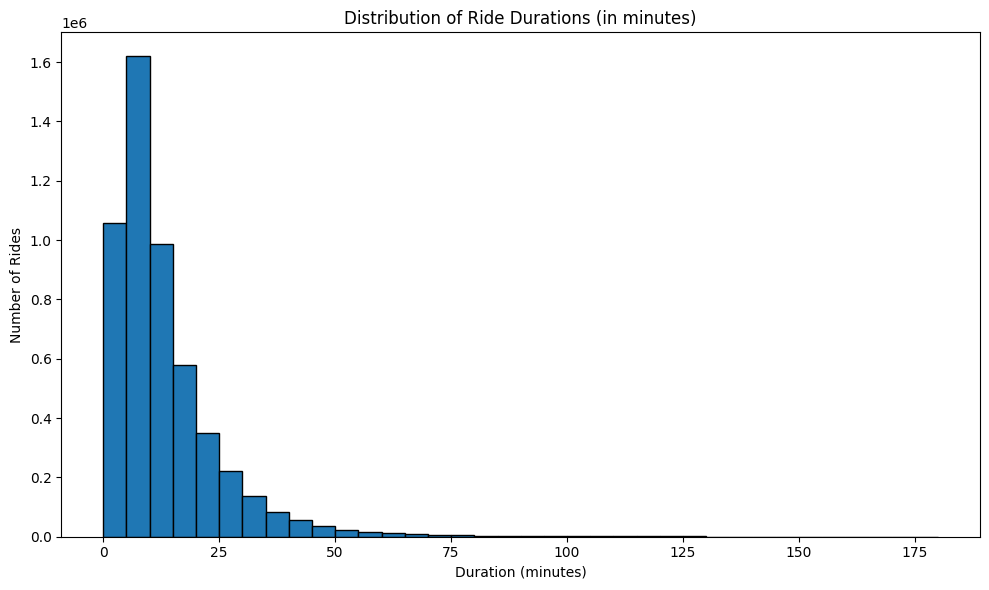

In [29]:
#Warmup 1
#Duration Histogram
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df_clean['duration_min'], bins=np.arange(0, 181, 5), edgecolor='black')

ax.set_title('Distribution of Ride Durations (in minutes)')
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Number of Rides')
plt.tight_layout()
plt.show()

In [30]:
#Warmup 2
#expected ride duration (average ride duration)?
avg_duration_min = df_clean['duration_min'].mean()
#what is the empirical variance of ride duration?
empirical_variance = df_clean['duration_min'].var()
#what is the probability that a ride lasts more than 20 minutes
prob_duration_over_20 = len(df_clean[df_clean['duration_min'] > 20]) / len(df_clean)

print(f"Average ride duration: {avg_duration_min:.2f} minutes")
print(f"Empirical variance of ride duration: {empirical_variance:.2f}")
print(f"Probability of ride lasting more than 20 minutes: {prob_duration_over_20:.2f}")

Average ride duration: 13.41 minutes
Empirical variance of ride duration: 157.22
Probability of ride lasting more than 20 minutes: 0.19


In [31]:
#Warmup 3
#what is the probability that a ride lasts more than 20 minutes conditional on the user being a Citi Bike member?
members = df_clean[df_clean['member_casual'] == 'member']
prob_greater_than_20_given_member = (members['duration_min'] > 20).mean()
print(f"Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: {prob_greater_than_20_given_member:.2f}")


Probability of ride lasting more than 20 minutes given the user is a Citi Bike member: 0.15


In [32]:
#Warmup 4
#Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs to a Citi Bike member?
#given a ride lasts more than 25 min, prob they are citi bike member

rides_longer_than_25_min = len(df_clean[df_clean['duration_min'] > 25])  # number of rides lasting more than 25 minutes
riders_longer_than_25_min_and_member = len(df_clean[(df_clean['duration_min'] > 25) & (df_clean['member_casual'] == 'member')])  # number of rides lasting more than 25 minutes and belonging to a member
prob_member_given_long_ride = riders_longer_than_25_min_and_member / rides_longer_than_25_min  # probability of being a member given the ride lasts more than 25 minutes
print(f"Probability of being a Citi Bike member given the ride lasts more than 25 minutes: {prob_member_given_long_ride:.2f}")

Probability of being a Citi Bike member given the ride lasts more than 25 minutes: 0.60


In [33]:
#Warmup 5
#What is the expected ride duration of an electric bike?
avg_ride_duration_electric = df_clean[df_clean['rideable_type'] == 'electric_bike']['duration_min'].mean()
#What is the expected ride duration of a classic bike?
avg_ride_duration_classic = df_clean[df_clean['rideable_type'] == 'classic_bike']['duration_min'].mean()
print(f"Expected ride duration of an electric bike: {avg_ride_duration_electric:.2f} minutes")
print(f"Expected ride duration of a classic bike: {avg_ride_duration_classic:.2f} minutes")

Expected ride duration of an electric bike: 13.36 minutes
Expected ride duration of a classic bike: 13.54 minutes


In [34]:
#Warmup 6
#Suppose that a ride lasts less than 10 minutes
#What is the probability it uses an electirc bike?
#What is the probability it uses a classic bike?
#Comment on the results
prob_electric_given_short_ride = len(df_clean[(df_clean['duration_min'] < 10) & (df_clean['rideable_type'] == 'electric_bike')]) / len(df_clean[df_clean['duration_min'] < 10])
prob_classic_given_short_ride = len(df_clean[(df_clean['duration_min'] < 10) & (df_clean['rideable_type'] == 'classic_bike')]) / len(df_clean[df_clean['duration_min'] < 10])
print(f"Probability of using an electric bike given the ride lasts less than 10 minutes: {prob_electric_given_short_ride:.2f}")
print(f"Probability of using a classic bike given the ride lasts less than 10 minutes: {prob_classic_given_short_ride:.2f}")        
print("Comment: The probabilities indicate that for rides lasting less than 10 minutes, there is a higher likelihood of using a classic bike compared to an electric bike. This could suggest that users prefer classic bikes for shorter trips, possibly due to convenience or availability.")

Probability of using an electric bike given the ride lasts less than 10 minutes: 0.72
Probability of using a classic bike given the ride lasts less than 10 minutes: 0.28
Comment: The probabilities indicate that for rides lasting less than 10 minutes, there is a higher likelihood of using a classic bike compared to an electric bike. This could suggest that users prefer classic bikes for shorter trips, possibly due to convenience or availability.
